In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping





C:\Users\singh\AppData\Local\Temp\ipykernel_11420\957439010.py:44: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(
[*********************100%***********************]  1 of 1 completed


Price           Close       High        Low       Open     Volume
Date                                                             
2010-01-04  15.483125  15.551307  15.421118  15.488065   78541293
2010-01-05  15.414941  15.510050  15.354416  15.493745  120638494
2010-01-06  15.026350  15.461137  14.979413  15.461137  159744526
2010-01-07  14.676543  15.069335  14.640723  15.054512  257533695
2010-01-08  14.872198  14.902584  14.553272  14.624665  189680313
Adding technical indicators...

Features Used:
['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD', 'MACD_SIGNAL', 'EMA20', 'SMA20', 'BB_UPPER', 'BB_LOWER', 'ATR']

Shape Information:
X_train: (2915, 100, 13)
X_test : (729, 100, 13)

Building LSTM model...


C:\Users\singh\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Training model...
Epoch 1/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 42s 324ms/step - loss: 0.0034 - val_loss: 0.0037
Epoch 2/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 292ms/step - loss: 0.0011 - val_loss: 0.0020
Epoch 3/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 17s 185ms/step - loss: 0.0011 - val_loss: 0.0021
Epoch 4/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 16s 173ms/step - loss: 8.9167e-04 - val_loss: 0.0028
Epoch 5/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 15s 161ms/step - loss: 0.0010 - val_loss: 0.0020
Epoch 6/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 150ms/step - loss: 6.0344e-04 - val_loss: 0.0015
Epoch 7/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 15s 164ms/step - loss: 6.5882e-04 - val_loss: 0.0046
Epoch 8/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 19s 206ms/step - loss: 6.5306e-04 - val_loss: 0.0016
Epoch 9/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 17s 183ms/step - loss: 4.7413e-04 - val_loss: 0.0015
Epoch 10/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 154ms/step - loss: 5.5133e-04 - val_loss: 0.0032
Epoch 11/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 140ms/step - loss: 5.1259e-04 - val_loss: 0

C:\Users\singh\AppData\Local\Temp\ipykernel_11420\957439010.py:281: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  dummy_pred[0, 3] = y_pred[i]
C:\Users\singh\AppData\Local\Temp\ipykernel_11420\957439010.py:281: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  dummy_pred[0, 3] = y_pred[i]
C:\Users\singh\AppData\Local\Temp\ipykernel_11420\957439010.py:281: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  dummy_pred[0, 3] = y_pred[i]
C:\Users\singh\AppData\Local\Temp\ipyker


================ METRICS ================
R2 Score : 0.9646898030663444
MAE      : 4.101693801909302
MSE      : 28.213376073298218
RMSE     : 5.311626499792528
MAPE     : 3.1370466408101456%


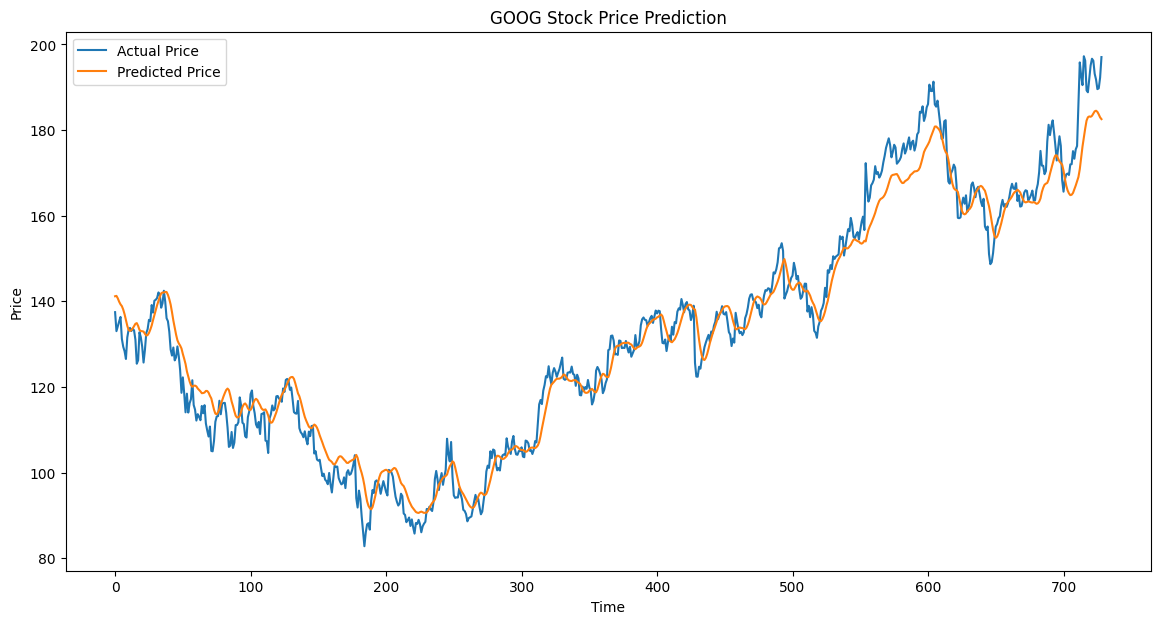

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import pandas_ta as ta

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    LSTM
)

from tensorflow.keras.callbacks import EarlyStopping


STOCK = "GOOG"

START_DATE = "2010-01-01"

END_DATE = "2025-01-07"

TIME_STEP = 100

MODEL_SAVE_PATH = "stock_lstm_model.keras"


print("Downloading stock data...")

df = yf.download(
    STOCK,
    start=START_DATE,
    end=END_DATE
)

df.columns=df.columns.get_level_values(0)

print(df.head())



print("Adding technical indicators...")

# RSI
df["RSI"] = ta.rsi(df["Close"], length=14)

# MACD
macd = ta.macd(df["Close"],length=14,fastperiod=12,slowperiod=26)

df["MACD"] = macd.iloc[:,0]

df["MACD_SIGNAL"] = macd.iloc[:,1]

# EMA
df["EMA20"] = ta.ema(df["Close"], length=20)

# SMA
df["SMA20"] = ta.sma(df["Close"], length=20)

# Bollinger Bands
bbands = ta.bbands(df["Close"], length=20)

df["BB_UPPER"] = bbands.iloc[:,0]

df["BB_LOWER"] = bbands.iloc[:,2]

# ATR
df["ATR"] = ta.atr(
    df["High"],
    df["Low"],
    df["Close"],
    length=14
)

df.dropna(inplace=True)



features = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "RSI",
    "MACD",
    "MACD_SIGNAL",
    "EMA20",
    "SMA20",
    "BB_UPPER",
    "BB_LOWER",
    "ATR"
]

data = df[features]

print("\nFeatures Used:")
print(features)



train_size = int(len(data) * 0.8)

train_data = data[:train_size]

test_data = data[train_size:]


scaler = MinMaxScaler(feature_range=(0, 1))

train_scaled = scaler.fit_transform(train_data)

test_scaled = scaler.transform(test_data)

full_scaled = np.vstack((train_scaled, test_scaled))



def prepare_data(data, time_step=100):

    X = []
    y = []

    for i in range(time_step, len(data)):


        X.append(data[i-time_step:i])


        y.append(data[i, 3])

    return np.array(X), np.array(y)

X, y = prepare_data(full_scaled, TIME_STEP)



split_index = int(len(X) * 0.8)

X_train = X[:split_index]

X_test = X[split_index:]

y_train = y[:split_index]

y_test = y[split_index:]

print("\nShape Information:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)



print("\nBuilding LSTM model...")

model = Sequential()

model.add(
    LSTM(
        units=100,
        return_sequences=True,
        input_shape=(
            X_train.shape[1],
            X_train.shape[2]
        )
    )
)

model.add(Dropout(0.2))

model.add(
    LSTM(
        units=100,
        return_sequences=False
    )
)

model.add(Dropout(0.2))

model.add(Dense(50))

model.add(Dense(1))



model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)



early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)



print("\nTraining model...")

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stopping]
)



model.save(MODEL_SAVE_PATH)

print("\nModel saved successfully!")


print("\nMaking predictions...")

y_pred = model.predict(X_test)


y_test_actual = []

y_pred_actual = []

for i in range(len(y_test)):

    dummy_test = np.zeros((1, len(features)))

    dummy_pred = np.zeros((1, len(features)))


    dummy_test[0, 3] = y_test[i]

    dummy_pred[0, 3] = y_pred[i]

    actual_price = scaler.inverse_transform(dummy_test)[0][3]

    predicted_price = scaler.inverse_transform(dummy_pred)[0][3]

    y_test_actual.append(actual_price)

    y_pred_actual.append(predicted_price)



mse = mean_squared_error(
    y_test_actual,
    y_pred_actual
)

rmse = np.sqrt(mse)

mae = mean_absolute_error(
    y_test_actual,
    y_pred_actual
)

r2 = r2_score(
    y_test_actual,
    y_pred_actual
)

mape = np.mean(
    np.abs(
        (
            np.array(y_test_actual)
            - np.array(y_pred_actual)
        )
        / np.array(y_test_actual)
    )
) * 100



print(f"R2 Score : {r2}")

print(f"MAE      : {mae}")

print(f"MSE      : {mse}")

print(f"RMSE     : {rmse}")

print(f"MAPE     : {mape}%")



plt.figure(figsize=(14, 7))

plt.plot(
    y_test_actual,
    label="Actual Price"
)

plt.plot(
    y_pred_actual,
    label="Predicted Price"
)

plt.title(f"{STOCK} Stock Price Prediction")

plt.xlabel("Time")

plt.ylabel("Price")

plt.legend()

plt.show()